# Explore the paired satellite observations

Inspect the actual input and reference, check class coverage and look at the dates held back for evaluation.

In [1]:
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs/dataset.yaml").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.schema import ROOT, NAMES, MODELS, config


## UTC partitions

In [2]:
from src.data import rows, scene, split
from src.schema import color_mask
data = ROOT / "data/processed"
partitions = split(rows(data))
pd.DataFrame([{"split": k, "scenes": len(v), "first": v[0]["timestamp"], "last": v[-1]["timestamp"]} for k,v in partitions.items() if v])

,split,scenes,first,last
0,train,177,2017-01-03T00:00:00+00:00,2017-09-11T18:00:00+00:00
1,val,36,2017-09-15T00:00:00+00:00,2017-11-03T18:00:00+00:00
2,test,39,2017-11-07T00:00:00+00:00,2017-12-27T18:00:00+00:00


## Independent measurements and target labels

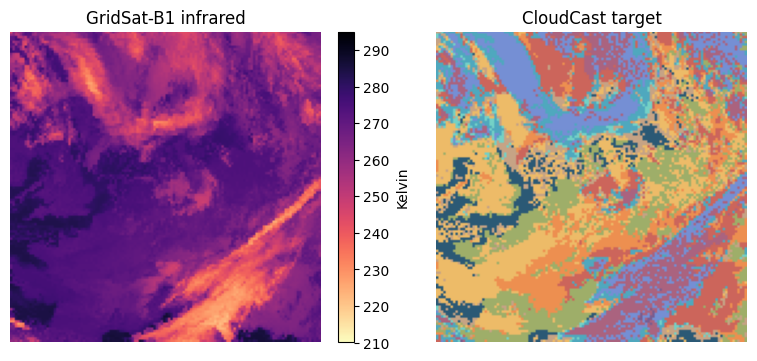

In [3]:
record = partitions["train"][0]
observed, reference = scene(data, record)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), layout="constrained")
image = axes[0].imshow(observed, cmap="magma_r", vmin=210, vmax=295)
fig.colorbar(image, ax=axes[0], label="Kelvin")
axes[0].set_title("GridSat-B1 infrared")
axes[1].imshow(color_mask(reference)); axes[1].set_title("CloudCast target")
for ax in axes: ax.axis("off")
fig

## Frequency by partition

In [4]:
audit = json.loads((ROOT/"experiments/data_audit.json").read_text())
freq = pd.DataFrame({s: audit["splits"][s]["counts"] for s in ("train","val","test")})
freq.sort_values("train", ascending=False)

,train,val,test
Clear land,594203,120931,92675
Mid-level cloud,344555,59239,66448
Very low cloud,341284,86316,93036
Low cloud,326474,86381,68950
High opaque cloud,256631,69473,69560
Fractional cloud,247320,28718,44596
Clear sea,223475,39050,26634
Moderate semitransparent cloud,211609,43049,56396
Thick semitransparent cloud,138645,20926,78050
Thin semitransparent cloud,110997,19282,19497
